# 09 — Physics-Informed Machine Learning

## Objective

This notebook investigates physics-informed machine learning for MEMS dynamical-system modelling.

Previous machine-learning approaches were trained primarily by minimizing prediction error. In contrast, physics-informed learning incorporates the governing dynamical equation directly into the learning objective.

For the deterministic linear MEMS baseline,

$$
m\ddot{x}
+
c\dot{x}
+
kx
=
F(t).
$$

A model that predicts acceleration,

$$
\hat{\ddot{x}},
$$

can therefore be evaluated not only through its prediction error but also through the physical residual

$$
r_{\mathrm{phys}}
=
m\hat{\ddot{x}}
+
c\dot{x}
+
kx
-
F(t).
$$

A physically consistent model should produce a small value of this residual.

The objectives of this notebook are to:

- construct a data-driven neural-network baseline,
- introduce a physics-informed loss function,
- compare purely data-driven and physics-informed training,
- evaluate prediction error and physical consistency,
- examine the effect of physics regularization under limited or noisy data.

This provides the physics-informed component of the broader Scientific Machine Learning workflow.

In [2]:
# NOTEBOOK SETUP

from pathlib import Path
import sys


# Identify the project root directory.
PROJECT_ROOT = Path.cwd().parent


# Add the project root to Python's import path.
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )


# Standard scientific Python libraries.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# Scikit-learn preprocessing and metrics.
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)


# PyTorch.
import torch
import torch.nn as nn


# Project utilities.
from src.utils import (
    data_path,
    results_path,
    figures_path,
    ensure_directory,
)

In [3]:
# LOAD DATA AND CREATE A LIMITED TRAINING SET

baseline_data_path = (
    data_path("raw")
    / "deterministic_baseline.csv"
)

baseline_data = pd.read_csv(
    baseline_data_path
)


# Extract the required variables.
time_values = baseline_data[
    "time"
].to_numpy()

displacement = baseline_data[
    "displacement"
].to_numpy()

velocity = baseline_data[
    "velocity"
].to_numpy()

excitation = baseline_data[
    "excitation"
].to_numpy()

acceleration = baseline_data[
    "acceleration"
].to_numpy()


# Build the input matrix:
#
# X = [displacement, velocity, excitation]
piml_input = np.column_stack(
    (
        displacement,
        velocity,
        excitation,
    )
)


piml_target = acceleration


# TIME-AWARE 80/20 SPLIT
train_fraction = 0.80

split_index = int(
    train_fraction
    * len(piml_input)
)


X_train_full = piml_input[
    :split_index
]

y_train_full = piml_target[
    :split_index
]

time_train_full = time_values[
    :split_index
]


X_test_piml = piml_input[
    split_index:
]

y_test_piml = piml_target[
    split_index:
]

time_test_piml = time_values[
    split_index:
]


# CREATE A LIMITED TRAINING SUBSET
number_of_training_samples = 400

limited_training_indices = np.linspace(
    0,
    len(X_train_full) - 1,
    number_of_training_samples,
    dtype=int,
)


X_train_piml = X_train_full[
    limited_training_indices
]

y_train_piml = y_train_full[
    limited_training_indices
]

time_train_piml = time_train_full[
    limited_training_indices
]


print(
    f"Original training samples: "
    f"{len(X_train_full)}"
)

print(
    f"Limited PIML training samples: "
    f"{len(X_train_piml)}"
)

print(
    f"Test samples: "
    f"{len(X_test_piml)}"
)

print()

print(
    f"Limited training time range: "
    f"{time_train_piml[0]:.4f} s "
    f"to {time_train_piml[-1]:.4f} s"
)

print(
    f"Test time range: "
    f"{time_test_piml[0]:.4f} s "
    f"to {time_test_piml[-1]:.4f} s"
)

Original training samples: 16000
Limited PIML training samples: 400
Test samples: 4001

Limited training time range: 0.0000 s to 1.5999 s
Test time range: 1.6000 s to 2.0000 s


In [4]:
# STANDARDIZE DATA FOR NEURAL-NETWORK TRAINING

# Create separate scalers for the inputs and target.
piml_input_scaler = StandardScaler()
piml_target_scaler = StandardScaler()


# Fit the input scaler ONLY on the limited training data.
X_train_piml_scaled = (
    piml_input_scaler.fit_transform(
        X_train_piml
    )
)

# Apply the same transformation to the held-out test data.
X_test_piml_scaled = (
    piml_input_scaler.transform(
        X_test_piml
    )
)


# Standardize the acceleration target.
y_train_piml_scaled = (
    piml_target_scaler
    .fit_transform(
        y_train_piml.reshape(-1, 1)
    )
)


# CONVERT NUMPY ARRAYS TO PYTORCH TENSORS
X_train_tensor = torch.tensor(
    X_train_piml_scaled,
    dtype=torch.float32,
)

y_train_tensor = torch.tensor(
    y_train_piml_scaled,
    dtype=torch.float32,
)

X_test_tensor = torch.tensor(
    X_test_piml_scaled,
    dtype=torch.float32,
)


# CHECK THE DATA
print(
    "Scaled training input means:"
)

print(
    np.mean(
        X_train_piml_scaled,
        axis=0,
    )
)

print()

print(
    "Scaled training input standard deviations:"
)

print(
    np.std(
        X_train_piml_scaled,
        axis=0,
    )
)

print()

print(
    f"Scaled target mean: "
    f"{np.mean(y_train_piml_scaled):.12e}"
)

print(
    f"Scaled target standard deviation: "
    f"{np.std(y_train_piml_scaled):.12f}"
)

print()

print(
    f"Training tensor shape: "
    f"{X_train_tensor.shape}"
)

print(
    f"Target tensor shape:   "
    f"{y_train_tensor.shape}"
)

print(
    f"Test tensor shape:     "
    f"{X_test_tensor.shape}"
)

Scaled training input means:
[-3.08086889e-17 -8.88178420e-18 -4.32986980e-17]

Scaled training input standard deviations:
[1. 1. 1.]

Scaled target mean: 2.220446049250e-18
Scaled target standard deviation: 1.000000000000

Training tensor shape: torch.Size([400, 3])
Target tensor shape:   torch.Size([400, 1])
Test tensor shape:     torch.Size([4001, 3])


In [5]:
# TRAIN THE DATA-DRIVEN NEURAL-NETWORK BASELINE

from src.physics_informed import (
    AccelerationNetwork,
    train_data_driven_model,
)


# Fix the random seed so that the neural-network
# initialization is reproducible.
torch.manual_seed(
    9512
)


# Create the neural-network model.
data_driven_model = AccelerationNetwork(
    input_size=3,
    hidden_size=32,
)


# Train using prediction error only.
(
    data_driven_model,
    data_driven_loss_history,
) = train_data_driven_model(
    model=data_driven_model,
    X_train=X_train_tensor,
    y_train=y_train_tensor,
    number_of_epochs=2000,
    learning_rate=1e-3,
    print_interval=400,
)

Epoch    1 | Data loss = 1.24652052e+00
Epoch  400 | Data loss = 2.34726816e-03
Epoch  800 | Data loss = 1.42064015e-03
Epoch 1200 | Data loss = 7.92294974e-04
Epoch 1600 | Data loss = 4.15560236e-04
Epoch 2000 | Data loss = 1.99552378e-04


In [6]:
# EVALUATE THE DATA-DRIVEN NEURAL NETWORK

# Switch the model to evaluation mode.
data_driven_model.eval()


# Disable gradient calculations because we are only
# performing prediction.
with torch.no_grad():

    data_driven_test_prediction_scaled = (
        data_driven_model(
            X_test_tensor
        )
        .cpu()
        .numpy()
    )


# Transform predictions back to physical acceleration units.
data_driven_test_prediction = (
    piml_target_scaler
    .inverse_transform(
        data_driven_test_prediction_scaled
    )
    .ravel()
)


# CALCULATE PREDICTION METRICS
data_driven_test_rmse = np.sqrt(
    mean_squared_error(
        y_test_piml,
        data_driven_test_prediction,
    )
)

data_driven_test_mae = mean_absolute_error(
    y_test_piml,
    data_driven_test_prediction,
)

data_driven_test_r2 = r2_score(
    y_test_piml,
    data_driven_test_prediction,
)


print(
    f"Data-driven NN testing RMSE: "
    f"{data_driven_test_rmse:.6f}"
)

print(
    f"Data-driven NN testing MAE:  "
    f"{data_driven_test_mae:.6f}"
)

print(
    f"Data-driven NN testing R²:   "
    f"{data_driven_test_r2:.12f}"
)

Data-driven NN testing RMSE: 0.037883
Data-driven NN testing MAE:  0.028668
Data-driven NN testing R²:   0.999875779179


In [7]:
# EVALUATE PHYSICAL CONSISTENCY OF THE DATA-DRIVEN MODEL

from src.physics_informed import (
    calculate_physics_residual,
)


# Extract the physical test variables.
test_displacement = X_test_piml[:, 0]
test_velocity = X_test_piml[:, 1]
test_excitation = X_test_piml[:, 2]


# Calculate the governing-equation residual produced
# by the data-driven neural-network prediction.
data_driven_physics_residual = (
    calculate_physics_residual(
        predicted_acceleration=
            data_driven_test_prediction,

        displacement=
            test_displacement,

        velocity=
            test_velocity,

        excitation=
            test_excitation,

        mass=1.0,
        damping=0.08,
        stiffness=1000.0,
    )
)


# PHYSICS-RESIDUAL METRICS
data_driven_physics_rmse = np.sqrt(
    np.mean(
        data_driven_physics_residual ** 2
    )
)

data_driven_physics_mae = np.mean(
    np.abs(
        data_driven_physics_residual
    )
)

data_driven_physics_max = np.max(
    np.abs(
        data_driven_physics_residual
    )
)


print(
    f"Data-driven physics residual RMSE: "
    f"{data_driven_physics_rmse:.6f}"
)

print(
    f"Data-driven physics residual MAE:  "
    f"{data_driven_physics_mae:.6f}"
)

print(
    f"Maximum absolute physics residual: "
    f"{data_driven_physics_max:.6f}"
)

Data-driven physics residual RMSE: 0.037883
Data-driven physics residual MAE:  0.028668
Maximum absolute physics residual: 0.116692


In [8]:
# CREATE PHYSICS COLLOCATION POINTS

# The neural network has only 400 labelled training samples.
#
# For the physics loss, however, we can use additional
# input locations without requiring acceleration labels.
#
# These are called collocation points.
#
# We select 2000 evenly spaced points from the complete
# training interval.

number_of_collocation_points = 2000


collocation_indices = np.linspace(
    0,
    len(X_train_full) - 1,
    number_of_collocation_points,
    dtype=int,
)


# Physical input values:
#
# [displacement, velocity, excitation]
X_collocation_physical = X_train_full[
    collocation_indices
]


# Standardize them using the SAME scaler that was fitted
# on the 400 labelled training samples.
X_collocation_scaled = (
    piml_input_scaler.transform(
        X_collocation_physical
    )
)


# Convert to PyTorch.
X_collocation_tensor = torch.tensor(
    X_collocation_scaled,
    dtype=torch.float32,
)


print(
    f"Labelled training samples: "
    f"{len(X_train_piml)}"
)

print(
    f"Physics collocation points: "
    f"{len(X_collocation_tensor)}"
)

print(
    f"Collocation tensor shape: "
    f"{X_collocation_tensor.shape}"
)

Labelled training samples: 400
Physics collocation points: 2000
Collocation tensor shape: torch.Size([2000, 3])


In [9]:
# CREATE PHYSICAL COLLOCATION TENSOR

X_collocation_physical_tensor = torch.tensor(
    X_collocation_physical,
    dtype=torch.float32,
)


print(
    f"Physical collocation tensor shape: "
    f"{X_collocation_physical_tensor.shape}"
)

Physical collocation tensor shape: torch.Size([2000, 3])


In [10]:
# TRAIN THE PHYSICS-INFORMED NEURAL NETWORK
from src.physics_informed import (
    AccelerationNetwork,
    train_physics_informed_model,
)


# Fix the seed so the initialization is reproducible.
torch.manual_seed(
    9512
)


# Create a fresh neural network.
physics_informed_model = AccelerationNetwork(
    input_size=3,
    hidden_size=32,
)


# Extract the target-scaling parameters.
target_mean = float(
    piml_target_scaler.mean_[0]
)

target_scale = float(
    piml_target_scaler.scale_[0]
)


# Train using:
#
# total loss
# = data loss
# + physics_weight * physics loss
(
    physics_informed_model,
    piml_total_loss_history,
    piml_data_loss_history,
    piml_physics_loss_history,
) = train_physics_informed_model(
    model=physics_informed_model,

    X_train=X_train_tensor,
    y_train=y_train_tensor,

    X_collocation=X_collocation_tensor,
    collocation_physical=
        X_collocation_physical_tensor,

    target_mean=target_mean,
    target_scale=target_scale,

    number_of_epochs=2000,
    learning_rate=1e-3,

    physics_weight=1.0,

    mass=1.0,
    damping=0.08,
    stiffness=1000.0,

    print_interval=400,
)

Epoch    1 | Total = 1.23696537e+01 | Data = 1.24652052e+00 | Physics = 1.11231337e+01
Epoch  400 | Total = 2.33319588e-02 | Data = 2.34812964e-03 | Physics = 2.09838282e-02
Epoch  800 | Total = 1.41184907e-02 | Data = 1.42111839e-03 | Physics = 1.26973726e-02
Epoch 1200 | Total = 7.87109882e-03 | Data = 7.92385021e-04 | Physics = 7.07871420e-03
Epoch 1600 | Total = 4.12512291e-03 | Data = 4.15318354e-04 | Physics = 3.70980450e-03
Epoch 2000 | Total = 1.97816035e-03 | Data = 1.99160422e-04 | Physics = 1.77900004e-03


In [11]:
# EVALUATE THE PHYSICS-INFORMED NEURAL NETWORK


# Switch the model to evaluation mode.
physics_informed_model.eval()


# Predict the held-out test interval.
with torch.no_grad():

    piml_test_prediction_scaled = (
        physics_informed_model(
            X_test_tensor
        )
        .cpu()
        .numpy()
    )


# Convert the prediction back to physical acceleration units.
piml_test_prediction = (
    piml_target_scaler
    .inverse_transform(
        piml_test_prediction_scaled
    )
    .ravel()
)



# PREDICTION METRICS
piml_test_rmse = np.sqrt(
    mean_squared_error(
        y_test_piml,
        piml_test_prediction,
    )
)

piml_test_mae = mean_absolute_error(
    y_test_piml,
    piml_test_prediction,
)

piml_test_r2 = r2_score(
    y_test_piml,
    piml_test_prediction,
)



# PHYSICS-RESIDUAL METRICS
piml_physics_residual = (
    calculate_physics_residual(
        predicted_acceleration=
            piml_test_prediction,

        displacement=
            test_displacement,

        velocity=
            test_velocity,

        excitation=
            test_excitation,

        mass=1.0,
        damping=0.08,
        stiffness=1000.0,
    )
)


piml_physics_rmse = np.sqrt(
    np.mean(
        piml_physics_residual ** 2
    )
)

piml_physics_mae = np.mean(
    np.abs(
        piml_physics_residual
    )
)

piml_physics_max = np.max(
    np.abs(
        piml_physics_residual
    )
)



# DISPLAY RESULTS
print(
    f"Physics-informed NN testing RMSE: "
    f"{piml_test_rmse:.6f}"
)

print(
    f"Physics-informed NN testing MAE:  "
    f"{piml_test_mae:.6f}"
)

print(
    f"Physics-informed NN testing R²:   "
    f"{piml_test_r2:.12f}"
)

print()

print(
    f"Physics-informed residual RMSE: "
    f"{piml_physics_rmse:.6f}"
)

print(
    f"Physics-informed residual MAE:  "
    f"{piml_physics_mae:.6f}"
)

print(
    f"Maximum absolute physics residual: "
    f"{piml_physics_max:.6f}"
)

Physics-informed NN testing RMSE: 0.037798
Physics-informed NN testing MAE:  0.028599
Physics-informed NN testing R²:   0.999876337043

Physics-informed residual RMSE: 0.037798
Physics-informed residual MAE:  0.028599
Maximum absolute physics residual: 0.116349


### Physics-Informed Model Performance

The physics-informed neural network achieved a held-out test RMSE of

$$
0.037798,
$$

compared with

$$
0.037883
$$

for the purely data-driven neural network.

The corresponding MAE decreased from

$$
0.028668
$$

to

$$
0.028599,
$$

while the coefficient of determination remained very high for both models:

$$
R^2 \approx 0.99988.
$$

The physics-informed model therefore produced a small improvement in both predictive accuracy and physical consistency.

The improvement is modest because the deterministic baseline represents a relatively simple relationship between displacement, velocity, excitation, and acceleration. Even with only 400 labelled samples, the data-driven neural network already approximates this relationship very accurately.

In addition, the physics constraint directly relates the network inputs to acceleration through

$$
\ddot{x}
=
F
-
0.08\dot{x}
-
1000x,
$$

so the collocation points provide strong physics-derived information throughout the training domain.

The result should therefore be interpreted as evidence that physics regularization provides a small consistency benefit in this clean limited-data experiment, rather than as a dramatic improvement over the already accurate data-driven baseline.

In [12]:
# COMPARE DATA-DRIVEN AND PHYSICS-INFORMED MODELS

piml_model_comparison = pd.DataFrame(
    {
        "model": [
            "Data-driven neural network",
            "Physics-informed neural network",
        ],

        "testing_rmse": [
            data_driven_test_rmse,
            piml_test_rmse,
        ],

        "testing_mae": [
            data_driven_test_mae,
            piml_test_mae,
        ],

        "testing_r2": [
            data_driven_test_r2,
            piml_test_r2,
        ],

        "physics_residual_rmse": [
            data_driven_physics_rmse,
            piml_physics_rmse,
        ],

        "physics_residual_mae": [
            data_driven_physics_mae,
            piml_physics_mae,
        ],

        "maximum_physics_residual": [
            data_driven_physics_max,
            piml_physics_max,
        ],
    }
)


piml_model_comparison

,model,testing_rmse,testing_mae,testing_r2,physics_residual_rmse,physics_residual_mae,maximum_physics_residual
0,Data-driven neural network,0.037883,0.028668,0.999876,0.037883,0.028668,0.116692
1,Physics-informed neural network,0.037798,0.028599,0.999876,0.037798,0.028599,0.116349


In [13]:
# CREATE NOISY LABELS FOR THE LIMITED-DATA EXPERIMENT

# Use a reproducible random-number generator.
piml_noise_rng = np.random.default_rng(
    9512
)


# Controlled acceleration measurement noise.
piml_noise_std = 0.05


# Add noise ONLY to the 400 labelled acceleration
# measurements.
#
# The physical collocation points themselves do not require
# acceleration labels, so they remain unchanged.
piml_training_noise = piml_noise_rng.normal(
    loc=0.0,
    scale=piml_noise_std,
    size=len(y_train_piml),
)


y_train_piml_noisy = (
    y_train_piml
    + piml_training_noise
)


# CHECK THE REALIZED NOISE
piml_realized_noise_mean = np.mean(
    piml_training_noise
)

piml_realized_noise_std = np.std(
    piml_training_noise
)


print(
    f"Requested noise std: "
    f"{piml_noise_std:.6f}"
)

print(
    f"Realized noise mean: "
    f"{piml_realized_noise_mean:.6f}"
)

print(
    f"Realized noise std:  "
    f"{piml_realized_noise_std:.6f}"
)

print(
    f"Number of noisy labelled samples: "
    f"{len(y_train_piml_noisy)}"
)

Requested noise std: 0.050000
Realized noise mean: -0.002823
Realized noise std:  0.048901
Number of noisy labelled samples: 400


In [14]:
# STANDARDIZE NOISY TRAINING LABELS

noisy_piml_target_scaler = StandardScaler()


y_train_piml_noisy_scaled = (
    noisy_piml_target_scaler
    .fit_transform(
        y_train_piml_noisy.reshape(-1, 1)
    )
)


y_train_noisy_tensor = torch.tensor(
    y_train_piml_noisy_scaled,
    dtype=torch.float32,
)


print(
    f"Scaled noisy target mean: "
    f"{np.mean(y_train_piml_noisy_scaled):.12e}"
)

print(
    f"Scaled noisy target standard deviation: "
    f"{np.std(y_train_piml_noisy_scaled):.12f}"
)

Scaled noisy target mean: -3.330669073875e-17
Scaled noisy target standard deviation: 1.000000000000


In [15]:
# TRAIN DATA-DRIVEN NN USING NOISY LABELS

from src.physics_informed import (
    AccelerationNetwork,
    train_data_driven_model,
)


# Same seed gives us a reproducible initialization.
torch.manual_seed(
    9512
)


noisy_data_driven_model = AccelerationNetwork(
    input_size=3,
    hidden_size=32,
)


(
    noisy_data_driven_model,
    noisy_data_driven_loss_history,
) = train_data_driven_model(
    model=noisy_data_driven_model,
    X_train=X_train_tensor,
    y_train=y_train_noisy_tensor,
    number_of_epochs=2000,
    learning_rate=1e-3,
    print_interval=400,
)

Epoch    1 | Data loss = 1.24669504e+00
Epoch  400 | Data loss = 2.78434693e-03
Epoch  800 | Data loss = 1.79317000e-03
Epoch 1200 | Data loss = 1.11242000e-03
Epoch 1600 | Data loss = 7.01110577e-04
Epoch 2000 | Data loss = 4.63663018e-04


In [16]:
# EVALUATE THE NOISY DATA-DRIVEN MODEL
# AGAINST THE CLEAN TEST TRAJECTORY


noisy_data_driven_model.eval()


# Predict acceleration for the held-out test interval.
with torch.no_grad():

    noisy_data_test_prediction_scaled = (
        noisy_data_driven_model(
            X_test_tensor
        )
        .cpu()
        .numpy()
    )


# IMPORTANT:
# Predictions must be transformed back using the scaler
# fitted to the noisy training labels.
noisy_data_test_prediction = (
    noisy_piml_target_scaler
    .inverse_transform(
        noisy_data_test_prediction_scaled
    )
    .ravel()
)



# PREDICTION METRICS AGAINST CLEAN TEST DATA
noisy_data_test_rmse = np.sqrt(
    mean_squared_error(
        y_test_piml,
        noisy_data_test_prediction,
    )
)

noisy_data_test_mae = mean_absolute_error(
    y_test_piml,
    noisy_data_test_prediction,
)

noisy_data_test_r2 = r2_score(
    y_test_piml,
    noisy_data_test_prediction,
)



# PHYSICS-RESIDUAL METRICS
noisy_data_physics_residual = (
    calculate_physics_residual(
        predicted_acceleration=
            noisy_data_test_prediction,

        displacement=
            test_displacement,

        velocity=
            test_velocity,

        excitation=
            test_excitation,

        mass=1.0,
        damping=0.08,
        stiffness=1000.0,
    )
)


noisy_data_physics_rmse = np.sqrt(
    np.mean(
        noisy_data_physics_residual ** 2
    )
)

noisy_data_physics_mae = np.mean(
    np.abs(
        noisy_data_physics_residual
    )
)

noisy_data_physics_max = np.max(
    np.abs(
        noisy_data_physics_residual
    )
)


print(
    f"Noisy-label data-driven NN test RMSE: "
    f"{noisy_data_test_rmse:.6f}"
)

print(
    f"Noisy-label data-driven NN test MAE:  "
    f"{noisy_data_test_mae:.6f}"
)

print(
    f"Noisy-label data-driven NN test R²:   "
    f"{noisy_data_test_r2:.12f}"
)

print()

print(
    f"Noisy-label physics residual RMSE: "
    f"{noisy_data_physics_rmse:.6f}"
)

print(
    f"Noisy-label physics residual MAE:  "
    f"{noisy_data_physics_mae:.6f}"
)

print(
    f"Maximum absolute physics residual: "
    f"{noisy_data_physics_max:.6f}"
)

Noisy-label data-driven NN test RMSE: 0.040198
Noisy-label data-driven NN test MAE:  0.032064
Noisy-label data-driven NN test R²:   0.999860133190

Noisy-label physics residual RMSE: 0.040198
Noisy-label physics residual MAE:  0.032064
Maximum absolute physics residual: 0.112385


In [17]:
# TRAIN PHYSICS-INFORMED NN USING NOISY LABELS

from src.physics_informed import (
    AccelerationNetwork,
    train_physics_informed_model,
)


# Use the same seed so that the noisy data-driven and
# noisy physics-informed networks begin from the same
# reproducible initialization.
torch.manual_seed(
    9512
)


# Create a fresh neural network.
noisy_physics_informed_model = AccelerationNetwork(
    input_size=3,
    hidden_size=32,
)


# IMPORTANT:
#
# The acceleration labels were standardized with the
# noisy-label scaler, so the physics-informed model must
# use the corresponding mean and scale when converting
# its predictions back to physical acceleration units.

noisy_target_mean = float(
    noisy_piml_target_scaler.mean_[0]
)

noisy_target_scale = float(
    noisy_piml_target_scaler.scale_[0]
)


# Train using:
#
# 400 noisy labelled samples
#
# +
#
# 2000 physics collocation points.

(
    noisy_physics_informed_model,
    noisy_piml_total_loss_history,
    noisy_piml_data_loss_history,
    noisy_piml_physics_loss_history,
) = train_physics_informed_model(
    model=noisy_physics_informed_model,

    X_train=X_train_tensor,
    y_train=y_train_noisy_tensor,

    X_collocation=X_collocation_tensor,
    collocation_physical=
        X_collocation_physical_tensor,

    target_mean=noisy_target_mean,
    target_scale=noisy_target_scale,

    number_of_epochs=2000,
    learning_rate=1e-3,

    physics_weight=1.0,

    mass=1.0,
    damping=0.08,
    stiffness=1000.0,

    print_interval=400,
)

Epoch    1 | Total = 1.23741856e+01 | Data = 1.24669504e+00 | Physics = 1.11274900e+01
Epoch  400 | Total = 2.37866007e-02 | Data = 2.81446311e-03 | Physics = 2.09721383e-02
Epoch  800 | Total = 1.45154800e-02 | Data = 1.85490970e-03 | Physics = 1.26605704e-02
Epoch 1200 | Total = 8.22077785e-03 | Data = 1.18509983e-03 | Physics = 7.03567825e-03
Epoch 1600 | Total = 4.44353698e-03 | Data = 7.71023624e-04 | Physics = 3.67251341e-03
Epoch 2000 | Total = 2.27570208e-03 | Data = 5.24115283e-04 | Physics = 1.75158668e-03


In [18]:
# EVALUATE NOISY PHYSICS-INFORMED MODEL
# AGAINST CLEAN TEST DATA

noisy_physics_informed_model.eval()


# Predict the held-out test interval.
with torch.no_grad():

    noisy_piml_test_prediction_scaled = (
        noisy_physics_informed_model(
            X_test_tensor
        )
        .cpu()
        .numpy()
    )


# Convert predictions back to physical acceleration units
# using the noisy-label target scaler.
noisy_piml_test_prediction = (
    noisy_piml_target_scaler
    .inverse_transform(
        noisy_piml_test_prediction_scaled
    )
    .ravel()
)


# PREDICTION METRICS AGAINST CLEAN TEST DATA
noisy_piml_test_rmse = np.sqrt(
    mean_squared_error(
        y_test_piml,
        noisy_piml_test_prediction,
    )
)

noisy_piml_test_mae = mean_absolute_error(
    y_test_piml,
    noisy_piml_test_prediction,
)

noisy_piml_test_r2 = r2_score(
    y_test_piml,
    noisy_piml_test_prediction,
)


# PHYSICS-RESIDUAL METRICS
noisy_piml_physics_residual = (
    calculate_physics_residual(
        predicted_acceleration=
            noisy_piml_test_prediction,

        displacement=
            test_displacement,

        velocity=
            test_velocity,

        excitation=
            test_excitation,

        mass=1.0,
        damping=0.08,
        stiffness=1000.0,
    )
)


noisy_piml_physics_rmse = np.sqrt(
    np.mean(
        noisy_piml_physics_residual ** 2
    )
)

noisy_piml_physics_mae = np.mean(
    np.abs(
        noisy_piml_physics_residual
    )
)

noisy_piml_physics_max = np.max(
    np.abs(
        noisy_piml_physics_residual
    )
)


# DISPLAY RESULTS
print(
    f"Noisy-label PIML test RMSE: "
    f"{noisy_piml_test_rmse:.6f}"
)

print(
    f"Noisy-label PIML test MAE:  "
    f"{noisy_piml_test_mae:.6f}"
)

print(
    f"Noisy-label PIML test R²:   "
    f"{noisy_piml_test_r2:.12f}"
)

print()

print(
    f"Noisy-label PIML physics residual RMSE: "
    f"{noisy_piml_physics_rmse:.6f}"
)

print(
    f"Noisy-label PIML physics residual MAE:  "
    f"{noisy_piml_physics_mae:.6f}"
)

print(
    f"Maximum absolute physics residual: "
    f"{noisy_piml_physics_max:.6f}"
)

Noisy-label PIML test RMSE: 0.037590
Noisy-label PIML test MAE:  0.028309
Noisy-label PIML test R²:   0.999877690163

Noisy-label PIML physics residual RMSE: 0.037590
Noisy-label PIML physics residual MAE:  0.028309
Maximum absolute physics residual: 0.115911


### Physics-Informed Learning with Noisy Labels

The noisy-label experiment provides a clearer demonstration of the benefit of physics-informed learning.

The purely data-driven neural network trained on 400 noisy acceleration labels achieved

$$
\mathrm{RMSE}=0.040198
$$

and

$$
\mathrm{MAE}=0.032064
$$

when evaluated against the clean held-out trajectory.

Using the same noisy labelled data together with 2000 physics collocation points, the physics-informed neural network improved the test performance to

$$
\mathrm{RMSE}=0.037590
$$

and

$$
\mathrm{MAE}=0.028309.
$$

The coefficient of determination remained very high:

$$
R^2\approx0.999878.
$$

Relative to the noisy data-driven model, the physics-informed model reduced the test RMSE by approximately 6.5% and the MAE by approximately 11.7%.

This provides evidence that the governing-equation constraint acts as a useful regularizer when the available labels contain measurement noise. Rather than fitting only the noisy observations, the model is simultaneously encouraged to remain consistent with the known MEMS dynamics.

The result therefore demonstrates a more meaningful advantage of physics-informed learning than the clean-data experiment, where both models were already highly accurate.

In [19]:
# COMPARE ALL NEURAL-NETWORK EXPERIMENTS
complete_piml_comparison = pd.DataFrame(
    {
        "experiment": [
            "Clean data-driven NN",
            "Clean physics-informed NN",
            "Noisy-label data-driven NN",
            "Noisy-label physics-informed NN",
        ],

        "testing_rmse": [
            data_driven_test_rmse,
            piml_test_rmse,
            noisy_data_test_rmse,
            noisy_piml_test_rmse,
        ],

        "testing_mae": [
            data_driven_test_mae,
            piml_test_mae,
            noisy_data_test_mae,
            noisy_piml_test_mae,
        ],

        "testing_r2": [
            data_driven_test_r2,
            piml_test_r2,
            noisy_data_test_r2,
            noisy_piml_test_r2,
        ],

        "physics_residual_rmse": [
            data_driven_physics_rmse,
            piml_physics_rmse,
            noisy_data_physics_rmse,
            noisy_piml_physics_rmse,
        ],

        "maximum_physics_residual": [
            data_driven_physics_max,
            piml_physics_max,
            noisy_data_physics_max,
            noisy_piml_physics_max,
        ],
    }
)

complete_piml_comparison

,experiment,testing_rmse,testing_mae,testing_r2,physics_residual_rmse,maximum_physics_residual
0,Clean data-driven NN,0.037883,0.028668,0.999876,0.037883,0.116692
1,Clean physics-informed NN,0.037798,0.028599,0.999876,0.037798,0.116349
2,Noisy-label data-driven NN,0.040198,0.032064,0.999860,0.040198,0.112385
3,Noisy-label physics-informed NN,0.037590,0.028309,0.999878,0.037590,0.115911


In [20]:
# SAVE PHYSICS-INFORMED ML RESULTS

physics_informed_results_directory = results_path(
    "physics_informed_ml"
)

ensure_directory(
    physics_informed_results_directory
)


# Save the complete four-model comparison.
piml_comparison_path = (
    physics_informed_results_directory
    / "physics_informed_model_comparison.csv"
)

complete_piml_comparison.to_csv(
    piml_comparison_path,
    index=False,
)


# SAVE NOISY-LABEL IMPROVEMENT SUMMARY
noisy_rmse_improvement_percent = (
    (
        noisy_data_test_rmse
        - noisy_piml_test_rmse
    )
    / noisy_data_test_rmse
    * 100.0
)


noisy_mae_improvement_percent = (
    (
        noisy_data_test_mae
        - noisy_piml_test_mae
    )
    / noisy_data_test_mae
    * 100.0
)


piml_noise_improvement = pd.DataFrame(
    {
        "metric": [
            "RMSE reduction percent",
            "MAE reduction percent",
        ],

        "value": [
            noisy_rmse_improvement_percent,
            noisy_mae_improvement_percent,
        ],
    }
)


piml_noise_improvement_path = (
    physics_informed_results_directory
    / "noisy_label_physics_improvement.csv"
)

piml_noise_improvement.to_csv(
    piml_noise_improvement_path,
    index=False,
)


print(
    "PIML model comparison saved to:"
)
print(
    piml_comparison_path
)

print()

print(
    "Noisy-label improvement saved to:"
)
print(
    piml_noise_improvement_path
)

print()

print(
    f"Noisy-label RMSE reduction: "
    f"{noisy_rmse_improvement_percent:.4f}%"
)

print(
    f"Noisy-label MAE reduction: "
    f"{noisy_mae_improvement_percent:.4f}%"
)

PIML model comparison saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\results\physics_informed_ml\physics_informed_model_comparison.csv

Noisy-label improvement saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\results\physics_informed_ml\noisy_label_physics_improvement.csv

Noisy-label RMSE reduction: 6.4867%
Noisy-label MAE reduction: 11.7108%


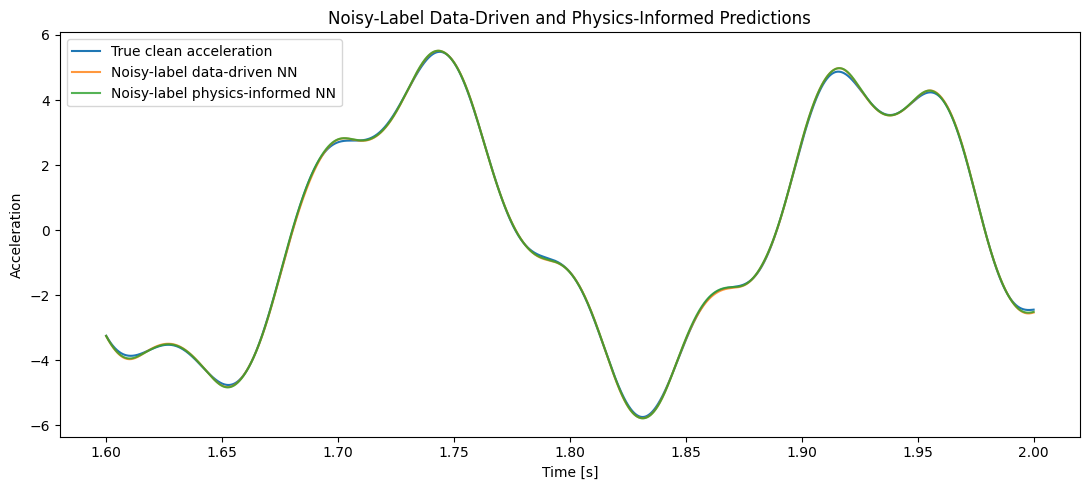

Noisy-label model comparison figure saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\figures\physics_informed_ml\noisy_label_model_comparison.png


In [22]:
# PLOT NOISY-LABEL MODEL COMPARISON
plt.figure(
    figsize=(11, 5)
)


# True clean acceleration.
plt.plot(
    time_test_piml,
    y_test_piml,
    label="True clean acceleration",
)


# Data-driven model trained on noisy labels.
plt.plot(
    time_test_piml,
    noisy_data_test_prediction,
    label="Noisy-label data-driven NN",
    alpha=0.8,
)


# Physics-informed model trained on the same noisy labels.
plt.plot(
    time_test_piml,
    noisy_piml_test_prediction,
    label="Noisy-label physics-informed NN",
    alpha=0.8,
)


plt.xlabel(
    "Time [s]"
)

plt.ylabel(
    "Acceleration"
)

plt.title(
    "Noisy-Label Data-Driven and "
    "Physics-Informed Predictions"
)

plt.legend()

plt.tight_layout()


# SAVE THE FIGURE
physics_informed_figure_directory = figures_path(
    "physics_informed_ml"
)

ensure_directory(
    physics_informed_figure_directory
)


piml_noisy_comparison_figure_path = (
    physics_informed_figure_directory
    / "noisy_label_model_comparison.png"
)


plt.savefig(
    piml_noisy_comparison_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


print(
    "Noisy-label model comparison figure saved to:"
)

print(
    piml_noisy_comparison_figure_path
)

### Noisy-Label Prediction Comparison

The data-driven and physics-informed neural networks both reproduce the clean held-out acceleration trajectory with high accuracy.

The differences are visually small because both models already achieve very high predictive performance. However, the quantitative evaluation shows that the physics-informed model performs better when trained on noisy labels.

The physics-informed model reduced the test RMSE by approximately

$$
6.49\%
$$

and the test MAE by approximately

$$
11.71\%.
$$

This indicates that the physics constraint acts as a useful regularizer and helps the neural network remain closer to the underlying clean dynamics despite noise in the labelled training data.

In [23]:
# FINAL OUTPUT VALIDATION FOR NOTEBOOK 09
notebook_09_outputs = {
    "piml_model_comparison":
        piml_comparison_path,

    "noisy_label_improvement":
        piml_noise_improvement_path,

    "noisy_label_prediction_figure":
        piml_noisy_comparison_figure_path,
}


for output_name, output_path in notebook_09_outputs.items():

    print(
        f"{output_name:35s} "
        f"{output_path.exists()}"
    )

piml_model_comparison               True
noisy_label_improvement             True
noisy_label_prediction_figure       True


# Notebook 09 Summary

This notebook investigated physics-informed machine learning for acceleration prediction in the MEMS dynamical system.

A neural-network model was trained using only 400 labelled samples from the first 80% of the trajectory. The remaining 4001 samples were reserved for time-aware testing.

## Data-Driven Neural Network

The purely data-driven neural network achieved

$$
\mathrm{RMSE}=0.037883,
$$

$$
\mathrm{MAE}=0.028668,
$$

and

$$
R^2\approx0.999876.
$$

The model therefore learned the deterministic relationship very accurately despite the limited number of labelled training samples.

## Physics-Informed Neural Network

A physics-informed model was then trained using the same 400 labelled samples together with 2000 physics collocation points.

The governing equation

$$
m\ddot{x}+c\dot{x}+kx-F=0
$$

was incorporated into the training objective through a physics-residual penalty.

For clean labelled data, the physics-informed model achieved

$$
\mathrm{RMSE}=0.037798,
$$

which represented only a small improvement over the data-driven baseline.

The limited difference is expected because the underlying deterministic relationship is simple and the data-driven neural network already approximates it very accurately.

## Noisy-Label Experiment

To investigate the regularizing effect of physical knowledge, Gaussian noise with

$$
\sigma=0.05
$$

was added to the 400 labelled acceleration samples.

The noisy-label data-driven neural network achieved

$$
\mathrm{RMSE}=0.040198
$$

and

$$
\mathrm{MAE}=0.032064
$$

against the clean held-out trajectory.

Using the same noisy labels together with the physics collocation points, the physics-informed model improved the test performance to

$$
\mathrm{RMSE}=0.037590
$$

and

$$
\mathrm{MAE}=0.028309.
$$

The corresponding reductions were approximately

$$
6.49\%
$$

for RMSE and

$$
11.71\%
$$

for MAE.

## Main Finding

The clean-data experiment showed only a modest benefit from physics-informed regularization because the deterministic mapping was already easy for the neural network to learn.

The noisy-label experiment provided a clearer result. The governing-equation constraint helped the neural network resist measurement noise and remain closer to the underlying clean physical response.

This demonstrates one of the main advantages of physics-informed machine learning: physical knowledge can act as a regularizer when labelled data are limited or imperfect.